# Supplementary Fig. 2b: power spectral densities of the high-pass filtered traces, by cortical layer

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel b of Supplementary Fig. 2 of the paper: power spectral densities (PSDs) divided by the total power of the in vivo (Marques-Smith, Horvath) and simulated (spontaneous and evoked Neuropixels, dense probe, synthetic model) traces high-pass filtered at 100 Hz and median-referenced, for each cortical layer, with power laws (1/f^alpha) fitted to the PSD (black lines). Source data and svg are saved in figures/8_source_data/supp_fig2b/.

**method (as in the paper's notebook supp_fig2_B_validation_fscaling_revised.ipynb)**
* PSD of every recording site in the cortex with the Welch method (1 Hz resolution, Hann window) of the traces high-pass filtered at 100 Hz and median-referenced (`src/pipes/validation/psd/multiprocess.py`, written in `dataset/01_intermediate/psds/psd_prep_*_cutoff_100.npy`: power of the sites x frequency)
* sites of each layer: Neuropixels (Marques-Smith, spontaneous, evoked): the sites of the layer; dense probes (Horvath and simulated): layers 1 and 2/3 from depth 1, layers 4 and 5 from depth 2, layer 6 from depth 3. The synthetic model (blue) has only layer 5 sites and is shown in the layer 5 panel only
* the PSD of each site is divided by its total power; the figure shows the mean over the sites of the log10 normalised power at each frequency (dots) and a power law fitted to the 100-10,000 Hz band (0.1-10 kHz, spiking activity; a linear regression of the log power on the log frequency of each site, averaged over the sites; black lines)

In [1]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
import spikeinterface as si
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# set project path
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(PROJ_PATH)

# custom package
import matplotlib
from sklearn.linear_model import LinearRegression
from matplotlib.lines import Line2D
import re

# paths: recordings (layer of each site) and power spectral densities of the traces high-pass filtered at 100 Hz and median-referenced
RAW = {"M": "dataset/00_raw/recording_marques_smith", "NS": "dataset/00_raw/recording_npx_spont", "E": "dataset/00_raw/recording_npx_evoked",
       "H1": "dataset/00_raw/recording_horvath_probe1", "H2": "dataset/00_raw/recording_horvath_probe2", "H3": "dataset/00_raw/recording_horvath_probe3",
       "DS1": "dataset/00_raw/recording_dense_probe1", "DS2": "dataset/00_raw/recording_dense_probe2", "DS3": "dataset/00_raw/recording_dense_probe3"}
PSD = {"M": "psd_prep_marques_smith_cutoff_100", "NS": "psd_prep_npx_spont_cutoff_100", "E": "psd_prep_npx_evoked_cutoff_100", "S": "psd_prep_buccino_cutoff_100",
       "H1": "psd_prep_horvath_probe1_cutoff_100", "H2": "psd_prep_horvath_probe2_cutoff_100", "H3": "psd_prep_horvath_probe3_cutoff_100",
       "DS1": "psd_prep_dense_probe1_cutoff_100", "DS2": "psd_prep_dense_probe2_cutoff_100", "DS3": "psd_prep_dense_probe3_cutoff_100"}
LAYERS = ["L1", "L2_3", "L4", "L5", "L6"]
LAYER_LABELS = {"L1": "L1", "L2_3": "L2/3", "L4": "L4", "L5": "L5", "L6": "L6"}
PROBE_OF_LAYER = {"L1": 1, "L2_3": 1, "L4": 2, "L5": 2, "L6": 3}      # depth of the dense probes that covers each layer
LFP_BAND, SPIKING_BAND = (0, 90), (100, 10000)      # Hz, frequency bands of the power-law fits
LABELS = {"M": "M : Marques-Smith", "NS": "NS : Biophy. spont.", "E": "E: Biophy. evoked", "S": "S: Synthetic", "H": "H: Horvath", "DS": "DS: Biophy. spont"}
COLORS = {"M": (0.6, 0.6, 0.6), "NS": (0.9, 0.14, 0.15), "E": (1, 0.49, 0), "S": (0.22, 0.5, 0.72), "H": (0.0, 0.0, 0.0), "DS": np.array([26, 152, 80]) / 255}

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 1.1
plt.rcParams["axes.linewidth"] = 1
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
legend_cfg = {"frameon": False, "handletextpad": 0.5}

# save config
savefig_cfg = {"transparent": True, "dpi": 300}# paths
DATA_PATH = "dataset/01_intermediate/supplementary/lfp_validation/lfp_infinitesimal_vs_finite.csv"

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 1.1
plt.rcParams["axes.linewidth"] = 1
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
legend_cfg = {"frameon": False, "handletextpad": 0.5}

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

In [ ]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Load the power spectral densities and the layer of the sites

In [2]:
%%time

def site_layers(recording_key, layers):
    """layer of the sites of the recording that have a power spectral density (sites of `layers`, merging layers 2 and 3)"""
    sites = np.array(["L2_3" if x in ("L2", "L3") else x for x in si.load_extractor(RAW[recording_key]).get_property("layers")])
    return sites[np.isin(sites, layers)]

psd = {k: np.load(f"dataset/01_intermediate/psds/{v}.npy", allow_pickle=True).item() for k, v in PSD.items()}
site_layer = {"M": site_layers("M", LAYERS), "NS": site_layers("NS", LAYERS), "E": site_layers("E", LAYERS),
              "H1": site_layers("H1", ["L1", "L2_3"]), "H2": site_layers("H2", ["L4", "L5"]), "H3": site_layers("H3", ["L6"]),
              "DS1": site_layers("DS1", ["L1", "L2_3"]), "DS2": site_layers("DS2", ["L4", "L5"]), "DS3": site_layers("DS3", ["L6"])}
for k, v in psd.items():
    assert v["freq"][1] == 1.0, "psd resolution should be 1 Hz"
    if k in site_layer: assert v["power"].shape[0] == len(site_layer[k]), (k, v["power"].shape, len(site_layer[k]))
    print(f"{k:3s} sites: {v['power'].shape[0]:4d} | frequencies up to {v['freq'][-1]:.0f} Hz")

M   sites:  226 | frequencies up to 15000 Hz
NS  sites:  202 | frequencies up to 20000 Hz
E   sites:  202 | frequencies up to 10000 Hz
S   sites:  200 | frequencies up to 16000 Hz
H1  sites:   96 | frequencies up to 10000 Hz
H2  sites:  108 | frequencies up to 10000 Hz
H3  sites:   68 | frequencies up to 10000 Hz
DS1 sites:  101 | frequencies up to 10000 Hz
DS2 sites:  120 | frequencies up to 10000 Hz
DS3 sites:   76 | frequencies up to 10000 Hz
CPU times: user 8.57 ms, sys: 26.9 ms, total: 35.5 ms
Wall time: 35.5 ms


## Normalised power and power-law fits by layer and experiment

In [3]:
%%time

def normalised_power(experiment, layer):
    """PSD of the sites of the layer, each divided by its total power"""
    if experiment in ("M", "NS", "E"):
        p, freq = psd[experiment]["power"][site_layer[experiment] == layer], psd[experiment]["freq"]
    elif experiment in ("H", "DS"):
        k = f"{experiment}{PROBE_OF_LAYER[layer]}"
        p, freq = psd[k]["power"][site_layer[k] == layer], psd[k]["freq"]
    else:       # synthetic model: all its sites are in layer 5
        p, freq = psd["S"]["power"], psd["S"]["freq"]
    return p / p.sum(axis=1)[:, None], freq

def fit_band(freq, log_power, band):
    """power law of each site in the band: log10 power = slope x log10 frequency + intercept"""
    in_band = (freq > band[0]) & (freq <= band[1]) & (freq > 0)
    x = np.log10(freq[in_band]).reshape(-1, 1)
    fits = [LinearRegression().fit(x, log_power[s, in_band]) for s in range(log_power.shape[0])]
    return np.array([f.coef_[0] for f in fits]), np.array([f.intercept_ for f in fits]), float(freq[in_band].min()), float(freq[in_band].max())

points, fits = [], []
for layer in LAYERS:
    for experiment in ["H", "M", "NS", "E", "DS"] + (["S"] if layer == "L5" else []):
        power, freq = normalised_power(experiment, layer)
        keep = freq > 0
        log_power = np.log10(power[:, keep])
        points.append(pd.DataFrame({"layer": LAYER_LABELS[layer], "experiment": LABELS[experiment], "frequency_Hz": freq[keep], "log10_normalised_power_mean_over_sites": log_power.mean(axis=0)}))
        for band_name, band in [("spiking (100-10,000 Hz)", SPIKING_BAND)]:
            slopes, intercepts, low, high = fit_band(freq[keep], log_power, band)
            fits.append(dict(layer=LAYER_LABELS[layer], experiment=LABELS[experiment], band=band_name, n_sites=power.shape[0], slope_mean=slopes.mean(), slope_std=slopes.std(),
                             intercept_mean=intercepts.mean(), band_low_Hz=low, band_high_Hz=high))
df_points, df_fits = pd.concat(points, ignore_index=True), pd.DataFrame(fits)
display(df_fits.pivot(index="experiment", columns="layer", values="slope_mean").round(2))

layer,L1,L2/3,L4,L5,L6
experiment,,,,,
DS: Biophy. spont,-0.09,-0.10,-0.17,-0.18,-0.27
E: Biophy. evoked,-0.21,-0.23,-0.61,-0.80,-0.30
H: Horvath,-1.09,-1.33,-1.48,-1.49,-1.26
M : Marques-Smith,-0.61,-0.51,-0.43,-0.73,-0.86
NS : Biophy. spont.,-0.27,-0.22,-0.57,-0.80,-0.25
S: Synthetic,NaN,NaN,NaN,-0.51,NaN


CPU times: user 496 ms, sys: 16.9 ms, total: 513 ms
Wall time: 513 ms


## Plot, same as the paper's panel b

In [4]:
def plot_source_data(df_points: pd.DataFrame, df_fits: pd.DataFrame):
    """Mean normalised power spectral density of the traces of each experiment (dots) in each layer and power laws fitted to the 100-10,000 Hz band (black lines)"""

    inv = {v: k for k, v in LABELS.items()}
    fig = plt.figure(figsize=(3.0, 4.2))
    gs = fig.add_gridspec(6, 2, left=0.17, right=0.98, top=0.98, bottom=0.08, wspace=0.55, hspace=1.4)
    positions = {"L1": gs[0:2, 0], "L4": gs[3:5, 0], "L2/3": gs[0:2, 1], "L5": gs[2:4, 1], "L6": gs[4:6, 1]}        # arrangement of the paper
    for layer, position in positions.items():
        ax = fig.add_subplot(position)
        experiments = [e for e in ["H", "M", "NS", "E", "DS", "S"] if LABELS[e] in set(df_points[df_points["layer"] == layer]["experiment"])]
        for e in experiments:
            d = df_points[(df_points["layer"] == layer) & (df_points["experiment"] == LABELS[e])]
            ax.plot(d["frequency_Hz"], 10 ** d["log10_normalised_power_mean_over_sites"], color=COLORS[e], linestyle="None", marker="o", markersize=2.2,
                    markeredgecolor="w", markeredgewidth=0.1, rasterized=True)
        for e in experiments:
            d = df_points[(df_points["layer"] == layer) & (df_points["experiment"] == LABELS[e])]
            for _, f in df_fits[(df_fits["layer"] == layer) & (df_fits["experiment"] == LABELS[e])].iterrows():
                log_f = np.log10(d[(d["frequency_Hz"] > f["band_low_Hz"] - 1e-9) & (d["frequency_Hz"] <= f["band_high_Hz"])]["frequency_Hz"].values)
                ax.plot(10 ** log_f, 10 ** (log_f * f["slope_mean"] + f["intercept_mean"]), color="k", linewidth=0.7)

        # aesthetics
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_title(layer, fontsize=6.5, fontweight="bold", pad=4)
        ax.xaxis.set_major_locator(matplotlib.ticker.LogLocator(base=10, numticks=5))
        ax.xaxis.set_minor_locator(matplotlib.ticker.LogLocator(base=10.0, subs=(0.2, 0.4, 0.6, 0.8), numticks=5))
        ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
        ax.spines[["top", "right"]].set_visible(False)
        ax.spines["bottom"].set_position(("axes", -0.05)); ax.yaxis.set_ticks_position("left"); ax.spines["left"].set_position(("axes", -0.05))
        ax.tick_params(labelsize=6.5, length=3)
        ax.yaxis.set_major_locator(matplotlib.ticker.LogLocator(base=10, numticks=3))
        if layer in ("L1", "L4"):
            ax.set_ylabel("Normalzed power (ratio)", fontsize=6)
        if layer in ("L4", "L6"):
            ax.set_xlabel("Frequency (Hz)", fontsize=6)
    return fig

## Plot and save the figure and the source data

CPU times: user 14 s, sys: 189 ms, total: 14.2 s
Wall time: 14.2 s


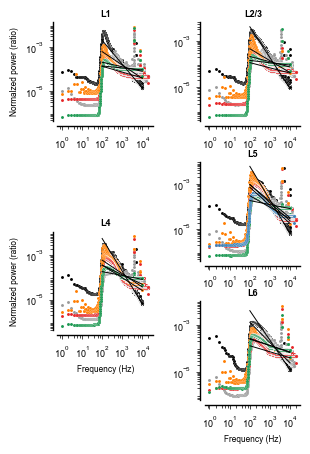

In [5]:
%%time

# plot
fig = plot_source_data(df_points, df_fits)

# save figure
os.makedirs("figures/8_source_data/supp_fig2b", exist_ok=True)
plt.savefig("figures/8_source_data/supp_fig2b/supp_fig2b.svg", bbox_inches="tight", **savefig_cfg)

# save source data (sheet 1: mean log normalised power at each frequency; sheet 2: power-law fits)
with pd.ExcelWriter("figures/8_source_data/supp_fig2b/supp_fig2b.xlsx") as writer:
    df_points.to_excel(writer, sheet_name="psd_mean_over_sites", index=False)
    df_fits.to_excel(writer, sheet_name="power_law_fits", index=False)

## Check: replot from the saved source data

CPU times: user 8.9 s, sys: 40 ms, total: 8.94 s
Wall time: 8.94 s


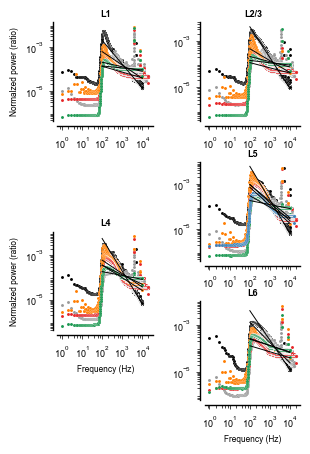

In [6]:
%%time

df_points = pd.read_excel("figures/8_source_data/supp_fig2b/supp_fig2b.xlsx", sheet_name="psd_mean_over_sites")
df_fits = pd.read_excel("figures/8_source_data/supp_fig2b/supp_fig2b.xlsx", sheet_name="power_law_fits")
fig = plot_source_data(df_points, df_fits)